# 03 · PGDA 5 m LOLA DEMs: terrain, error budget and terrain-aware horizons

**Lunar Landing Site Navigator.** This notebook explores the PGDA high-resolution LOLA topography
([product 78](https://pgda.gsfc.nasa.gov/products/78), Barker et al. 2021) for two south-pole candidate sites:

| PGDA id | Name | Horizons table |
|---|---|---|
| Site01 | Connecting Ridge | `site01_connecting_ridge_{sun,earth}.csv` |
| Site04 | Shackleton Rim | `site04_shackleton_rim_{sun,earth}.csv` |

Goals, in app terms:
1. What is in the files (extent, CRS, coverage, value ranges), and how much of the 5 m grid is actually *measured* vs *interpolated*.
2. Landing-suitability proxies (slope) and the PGDA "regions of interest" (ROIs).
3. **The key app algorithm:** a terrain horizon profile (horizon elevation vs azimuth) by ray-marching over the DEM, with lunar curvature.
4. Overlay JPL Horizons Sun/Earth tracks on that horizon and compare *terrain-aware* vs *smooth-horizon* sunlight and Earth-visibility.
5. Limits of a 16 km tile, and what a web app should precompute.

In [1]:
import io, struct, sys, tarfile, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.path import Path as MplPath
from affine import Affine
from pyproj import Transformer

from data.horizons import SITES as HZ_SITES
from data.pgda import POLAR_STEREO, RAW, SITES, read_xyzi, site_center_latlon

plt.rcParams.update({"figure.dpi": 80, "axes.grid": False})
R = 1737400.0                       # lunar sphere radius used by the DEM projection (m)
SUN_R = 0.2666                      # mean apparent solar radius (deg)
PG = {"Site01": "site01_connecting_ridge", "Site04": "site04_shackleton_rim"}
PRODUCTS = ["surf", "slp", "toterr", "ldec"]
tif = lambda s, p: RAW / s / f"{s}_final_adj_5mpp_{p}.tif"

## 1. Raster metadata, extents, coverage and value distributions

In [2]:
meta, ARR, TR, BND = [], {}, {}, {}
for s in PG:
    for p in PRODUCTS:
        with rasterio.open(tif(s, p)) as ds:
            a = ds.read(1)
            TR[s], BND[s], crs = ds.transform, ds.bounds, ds.crs
        ARR[s, p] = a
        v = a[np.isfinite(a)]
        b = BND[s]
        meta.append({"site": s, "product": p, "dtype": a.dtype, "shape": a.shape, "res_m": TR[s].a,
                     "x_km": f"{b.left/1e3:.0f}..{b.right/1e3:.0f}", "y_km": f"{b.bottom/1e3:.0f}..{b.top/1e3:.0f}",
                     "nodata_%": 100 * (1 - v.size / a.size), "min": v.min(), "p1": np.percentile(v, 1),
                     "median": np.median(v), "p99": np.percentile(v, 99), "max": v.max()})
print("CRS:", crs.to_proj4())
pd.DataFrame(meta).round(2)

CRS: +proj=stere +lat_0=-90 +lat_ts=-90 +lon_0=0 +x_0=0 +y_0=0 +R=1737400 +units=m +no_defs=True


,site,product,dtype,shape,res_m,x_km,y_km,nodata_%,min,p1,median,p99,max
0,Site01,surf,float32,"(3200, 3200)",5.0,-19..-3,-20..-4,0.0,-523.179993,-177.059998,1200.250000,1897.819946,1959.500000
1,Site01,slp,float32,"(3200, 3200)",5.0,-19..-3,-20..-4,0.0,0.000000,1.680000,12.290000,26.450001,64.589996
2,Site01,toterr,float32,"(3200, 3200)",5.0,-19..-3,-20..-4,0.0,0.060000,0.130000,0.370000,0.990000,5.580000
3,Site01,ldec,float32,"(3200, 3200)",5.0,-19..-3,-20..-4,0.0,0.000000,0.000000,0.000000,1.000000,5.000000
4,Site04,surf,float32,"(3200, 3200)",5.0,-9..7,-15..1,0.0,-2847.879883,-2735.689941,668.190002,1685.489990,1805.069946
5,Site04,slp,float32,"(3200, 3200)",5.0,-9..7,-15..1,0.0,0.000000,2.380000,20.549999,37.349998,69.650002
6,Site04,toterr,float32,"(3200, 3200)",5.0,-9..7,-15..1,0.0,0.060000,0.130000,0.360000,1.200000,7.640000
7,Site04,ldec,float32,"(3200, 3200)",5.0,-9..7,-15..1,0.0,0.000000,0.000000,0.000000,1.000000,5.000000


In [3]:
to_xy = Transformer.from_crs("+proj=longlat +R=1737400 +no_defs", POLAR_STEREO, always_xy=True)
for s, hz in PG.items():
    lat, lon = site_center_latlon(tif(s, "surf"))
    hlat, hlon = HZ_SITES[hz]
    x, y = to_xy.transform(hlon, hlat)
    print(f"{s} ({SITES[s]}): DEM center lat {lat:.4f} lon {lon:.4f}E | Horizons point lat {hlat} lon {hlon}E "
          f"-> x={x:.0f} m y={y:.0f} m, {np.hypot(x, y)/1e3:.1f} km from the pole")
o = (max(BND["Site01"].left, BND["Site04"].left), min(BND["Site01"].right, BND["Site04"].right),
     max(BND["Site01"].bottom, BND["Site04"].bottom), min(BND["Site01"].top, BND["Site04"].top))
print(f"The two tiles overlap over x {o[0]/1e3:.0f}..{o[1]/1e3:.0f} km, y {o[2]/1e3:.0f}..{o[3]/1e3:.0f} km "
      f"({(o[1]-o[0])*(o[3]-o[2])/1e6:.0f} km2) -- used in section 6.")

Site01 (Connecting ridge): DEM center lat -89.4632 lon 222.4980E | Horizons point lat -89.4632 lon 222.5104E -> x=-10999 m y=-11999 m, 16.3 km from the pole
Site04 (Shackleton rim): DEM center lat -89.7667 lon 188.1072E | Horizons point lat -89.763 lon 187.9976E -> x=-1000 m y=-7117 m, 7.2 km from the pole
The two tiles overlap over x -9..-3 km, y -15..-4 km (66 km2) -- used in section 6.


**Findings.** Both sites are 3200×3200 float32 grids at 5 m/px (16×16 km) in south polar stereographic
(sphere R = 1737.4 km, metres). There are **no NaN/nodata pixels** in any of the four products: the DEM is
gap-filled everywhere, so "no data" never tells you that a pixel is interpolated (use `ldec`, below).
Heights span ~2.5 km at Site01 and ~4.6 km at Site04 (Shackleton's interior floor is in the tile).
The Horizons tables were generated exactly at each DEM's centre point, so the ephemeris and DEM line up.

## 2. Maps: height, slope, height error, LOLA shot density

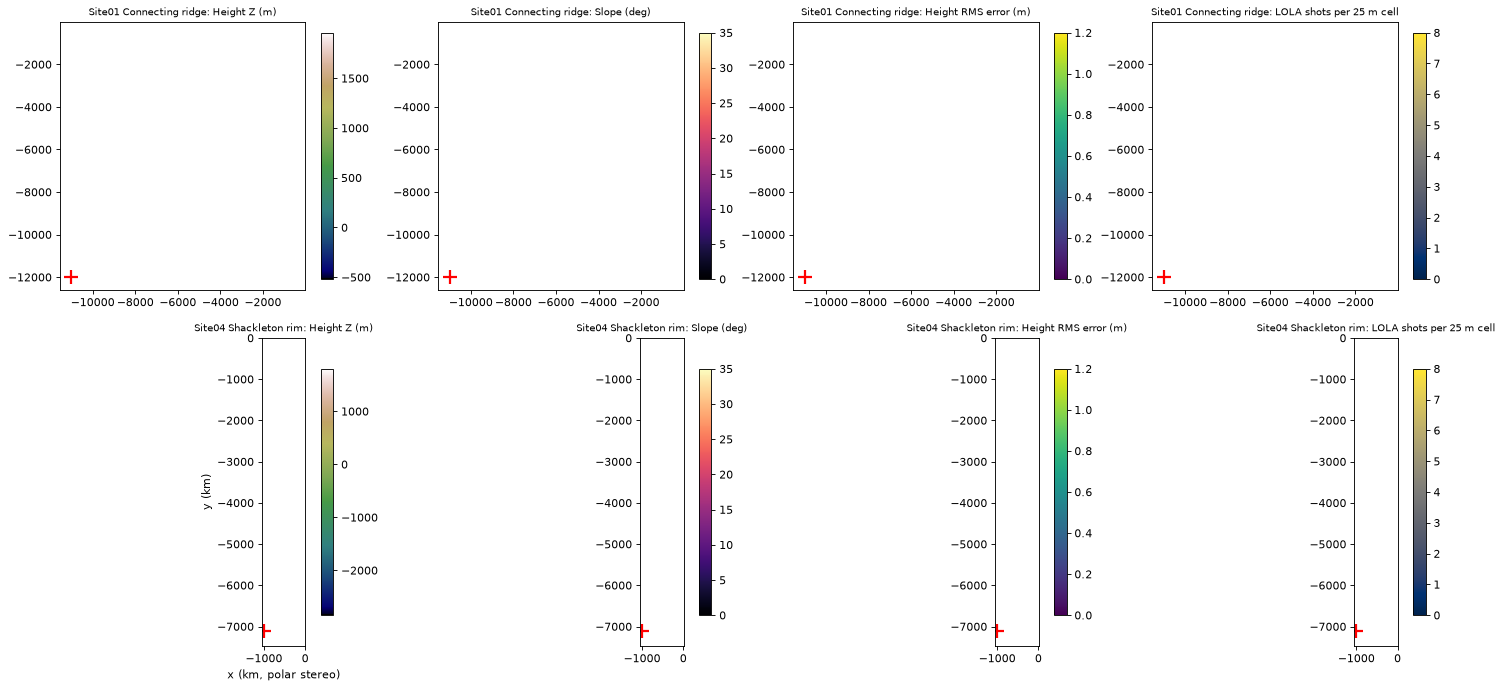

In [4]:
def coarse(a, f=5):
    n = a.shape[0] // f
    return a[:n * f, :n * f].reshape(n, f, n, f).mean((1, 3))

ext = lambda s: [BND[s].left / 1e3, BND[s].right / 1e3, BND[s].bottom / 1e3, BND[s].top / 1e3]
specs = [("surf", "Height Z (m)", "gist_earth", None, 1), ("slp", "Slope (deg)", "magma", (0, 35), 1),
         ("toterr", "Height RMS error (m)", "viridis", (0, 1.2), 1), ("ldec", "LOLA shots per 25 m cell", "cividis", (0, 8), 25)]
fig, axs = plt.subplots(2, 4, figsize=(18, 8.6), constrained_layout=True)
for i, s in enumerate(PG):
    for j, (p, label, cmap, lim, mult) in enumerate(specs):
        im = axs[i, j].imshow(coarse(ARR[s, p]) * mult, extent=ext(s), cmap=cmap,
                              vmin=lim and lim[0], vmax=lim and lim[1])
        axs[i, j].plot(*to_xy.transform(HZ_SITES[PG[s]][1], HZ_SITES[PG[s]][0]), "r+", ms=12, mew=2)
        axs[i, j].set_title(f"{s} {SITES[s]}: {label}", fontsize=9)
        fig.colorbar(im, ax=axs[i, j], shrink=0.8)
axs[1, 0].set_xlabel("x (km, polar stereo)"); axs[1, 0].set_ylabel("y (km)")
plt.show()

In [5]:
rows, binned = [], []
for s in PG:
    l, e = ARR[s, "ldec"], ARR[s, "toterr"]
    rows.append({"site": s, "px with 0 shots %": 100 * (l == 0).mean(), "px with 1 shot %": 100 * (l == 1).mean(),
                 "px with >=2 shots %": 100 * (l >= 2).mean(), "shots per km2": l.sum() / 256,
                 "err median (m)": np.median(e), "err p95 (m)": np.percentile(e, 95), "err max (m)": e.max(),
                 "err @0 shots (m)": np.median(e[l == 0]), "err @>=1 shot (m)": np.median(e[l > 0])})
    shots25 = coarse(l) * 25  # shots per 25x25 m block
    binned.append(pd.Series(coarse(e).ravel()).groupby(pd.cut(shots25.ravel(), [-1, 0, 1, 2, 4, 8, 1e9],
                  labels=["0", "1", "2", "3-4", "5-8", ">8"]), observed=False).median().rename(s))
display(pd.DataFrame(rows).round(2))
pd.concat(binned, axis=1).rename_axis("shots in 25 m block").round(3).T.style.set_caption("median height error (m) by local shot density")

,site,px with 0 shots %,px with 1 shot %,px with >=2 shots %,shots per km2,err median (m),err p95 (m),err max (m),err @0 shots (m),err @>=1 shot (m)
0,Site01,90.51,9.01,0.49,3999.679932,0.37,0.73,5.58,0.38,0.25
1,Site04,90.85,8.71,0.44,3843.409912,0.36,0.83,7.64,0.36,0.36


shots in 25 m block,0,1,2,3-4,5-8,>8
Site01,0.580000,0.438000,0.374000,0.327000,0.283000,0.251000
Site04,0.479000,0.401000,0.372000,0.351000,0.321000,0.289000


### Raw point cloud (`*_final_adj.xyzi`) vs the gridded DEM
x/y/z are polar-stereographic km (z = height above the 1737.4 km sphere, km); the 4th column is the LOLA RDR id `YYDOYHHMM`.

In [6]:
def bilinear(Z, tr, x, y):
    # Sample north-up grid Z (affine tr) at map coords (m); NaN outside the grid.
    c = (np.asarray(x) - tr.c) / tr.a - 0.5
    r = (np.asarray(y) - tr.f) / tr.e - 0.5
    c0, r0 = np.floor(c).astype(np.int64), np.floor(r).astype(np.int64)
    ok = (c0 >= 0) & (r0 >= 0) & (c0 < Z.shape[1] - 1) & (r0 < Z.shape[0] - 1)
    c0, r0 = np.where(ok, c0, 0), np.where(ok, r0, 0)
    fc, fr = c - c0, r - r0
    z = (Z[r0, c0] * (1 - fc) * (1 - fr) + Z[r0, c0 + 1] * fc * (1 - fr)
         + Z[r0 + 1, c0] * (1 - fc) * fr + Z[r0 + 1, c0 + 1] * fc * fr)
    return np.where(ok, z, np.nan)

rows = []
for s in PG:
    pc = read_xyzi(RAW / s / f"{s}_final_adj.xyzi")
    rdr = pc["rdr_id"].astype(np.int64)
    t = pd.to_datetime((2000 + rdr // 10**7).astype(str), format="%Y") + pd.to_timedelta((rdr // 10**4) % 1000 - 1, "D")
    res = pc["z"] * 1e3 - bilinear(ARR[s, "surf"], TR[s], pc["x"] * 1e3, pc["y"] * 1e3)
    res = res[np.isfinite(res)]
    rows.append({"site": s, "shots": len(pc), "sum(ldec)": int(ARR[s, "ldec"].sum()), "LOLA tracks (RDR ids)": len(np.unique(rdr)),
                 "first": t.min().date(), "last": t.max().date(), "shot-DEM median (m)": np.median(res),
                 "shot-DEM robust std (m)": 1.4826 * np.median(np.abs(res - np.median(res))),
                 "|shot-DEM| p99 (m)": np.percentile(np.abs(res), 99)})
pd.DataFrame(rows).round(3)

,site,shots,sum(ldec),LOLA tracks (RDR ids),first,last,shot-DEM median (m),shot-DEM robust std (m),|shot-DEM| p99 (m)
0,Site01,1023918,1023918,2333,2009-07-13,2011-11-19,0.002,0.242,0.851
1,Site04,983913,983913,2334,2009-07-16,2011-09-29,0.002,0.384,1.379


**Findings: measured vs interpolated, error budget.**
* About **90% of the 5 m pixels contain no LOLA shot at all** (`ldec = 0`); ~10% have one shot and <1% two or more
  (≈ 4 000 shots/km², i.e. one every ~16 m on average). The 5 m grid is therefore mostly an *interpolation between
  LOLA tracks* (PGDA fits a surface to ~1 M co-registered shots from ~2 300 LOLA RDR files ≈ orbits, July 2009 – Nov 2011; `sum(ldec)` equals the shot count exactly). The shot-density map shows the
  ground-track striping; gaps between tracks are where small boulders/craters can be missed.
* The `toterr` height RMS error is small: median ≈ 0.37 m, 95th percentile ≈ 0.7–0.8 m, max a few metres (on steep crater walls).
  Error grows modestly as local shot density falls (table above). For horizon work this is negligible: 1 m of height
  error at 1 km distance is 0.06° of horizon elevation, far below the solar radius (0.27°).
* The raw shots agree with the DEM to a robust std of a few tens of cm (median offset ≈ 0), confirming the gridded
  heights reproduce the measurements; the gap-filled pixels are where the uncertainty lies.
* App implication: show `toterr`/`ldec` as a "confidence" layer, and do not present 5 m features between tracks as certain
  (e.g. a slope hazard map at 5 m is partly interpolated).

## 3. Landing-suitability proxies: slope and PGDA ROIs
The ROI tarballs hold one shapefile each (`*_ROIs.shp`); the linked `.gmt` name says they are
`regionProps_avgillGT070` = regions whose **average illumination exceeds 70%** in the PGDA analysis.
geopandas is not installed, so the polygons are read with a ~15-line shapefile parser, straight from the tarball (no extraction).

In [7]:
def read_rois(site):
    # Polygons (list of (N,2) arrays, metres) from the ESRI .shp inside the ROI tarball; polygon type 5 only.
    with tarfile.open(RAW / site / f"{site}_ROIs.tgz") as tf:
        buf = tf.extractfile(f"{site}_ROIs.shp").read()
    polys, off = [], 100
    while off < len(buf):
        _, n16 = struct.unpack(">2i", buf[off:off + 8])
        rec, off = buf[off + 8: off + 8 + 2 * n16], off + 8 + 2 * n16
        if struct.unpack("<i", rec[:4])[0] != 5:
            continue
        nparts, npts = struct.unpack("<2i", rec[36:44])
        pts = np.frombuffer(rec, "<f8", 2 * npts, 44 + 4 * nparts).reshape(-1, 2)
        polys.append(pts)  # shortcut: parts are concatenated; fine for these single-ring ROIs
    return polys

def poly_mask(poly, s):
    b, tr = BND[s], TR[s]
    c0, c1 = int((poly[:, 0].min() - b.left) // 5), int((poly[:, 0].max() - b.left) // 5) + 1
    r0, r1 = int((b.top - poly[:, 1].max()) // 5), int((b.top - poly[:, 1].min()) // 5) + 1
    cc, rr = np.meshgrid(np.arange(c0, c1), np.arange(r0, r1))
    inside = MplPath(poly).contains_points(np.c_[tr.c + (cc.ravel() + .5) * 5, tr.f - (rr.ravel() + .5) * 5])
    m = np.zeros(ARR[s, "slp"].shape, bool)
    m[rr.ravel()[inside], cc.ravel()[inside]] = True
    return m

ROIS = {s: read_rois(s) for s in PG}
thr = [5, 10, 15, 20]
display(pd.DataFrame({s: {f"slope < {t} deg (% of tile)": 100 * (ARR[s, 'slp'] < t).mean() for t in thr} for s in PG}).round(1))

rows, ROI_MASK = [], {}
for s in PG:
    for k, poly in enumerate(ROIS[s]):
        m = ROI_MASK[s, k] = poly_mask(poly, s)
        sl = ARR[s, "slp"][m]
        rows.append({"site": s, "roi": k, "area_m2": m.sum() * 25, "cx_m": poly[:, 0].mean(), "cy_m": poly[:, 1].mean(),
                     "mean slope": sl.mean(), "% slope<5": 100 * (sl < 5).mean(), "% slope<10": 100 * (sl < 10).mean(),
                     "median err (m)": np.median(ARR[s, "toterr"][m]), "% px with shots": 100 * (ARR[s, "ldec"][m] > 0).mean()})
ROI_TAB = pd.DataFrame(rows)
ROI_TAB.round(2)

,Site01,Site04
slope < 5 deg (% of tile),9.8,4.7
slope < 10 deg (% of tile),36.4,18.8
slope < 15 deg (% of tile),66.0,37.0
slope < 20 deg (% of tile),88.1,49.0


,site,roi,area_m2,cx_m,cy_m,mean slope,% slope<5,% slope<10,median err (m),% px with shots
0,Site01,0,7050,-11589.93,-12466.35,2.38,99.65,100.0,0.45,5.32
1,Site01,1,5700,-11487.19,-12556.76,2.29,97.37,100.0,0.32,10.96
2,Site01,2,2775,-11352.78,-12503.98,2.10,97.30,100.0,0.28,15.32
3,Site01,3,10775,-11286.64,-12166.60,2.25,99.07,100.0,0.35,9.51
4,Site01,4,7550,-11101.06,-11945.47,2.03,99.34,100.0,0.30,11.26
5,Site01,5,8425,-10798.25,-11735.32,2.51,97.92,100.0,0.30,12.76
6,Site01,6,5475,-10227.38,-11557.99,1.94,98.63,100.0,0.34,10.96
7,Site04,0,4175,-2813.37,-6665.23,2.68,98.20,100.0,0.42,8.38
8,Site04,1,2075,-2758.53,-6348.76,2.35,96.39,100.0,0.25,13.25
9,Site04,2,1850,-2677.84,-6106.14,2.99,91.89,100.0,0.28,13.51


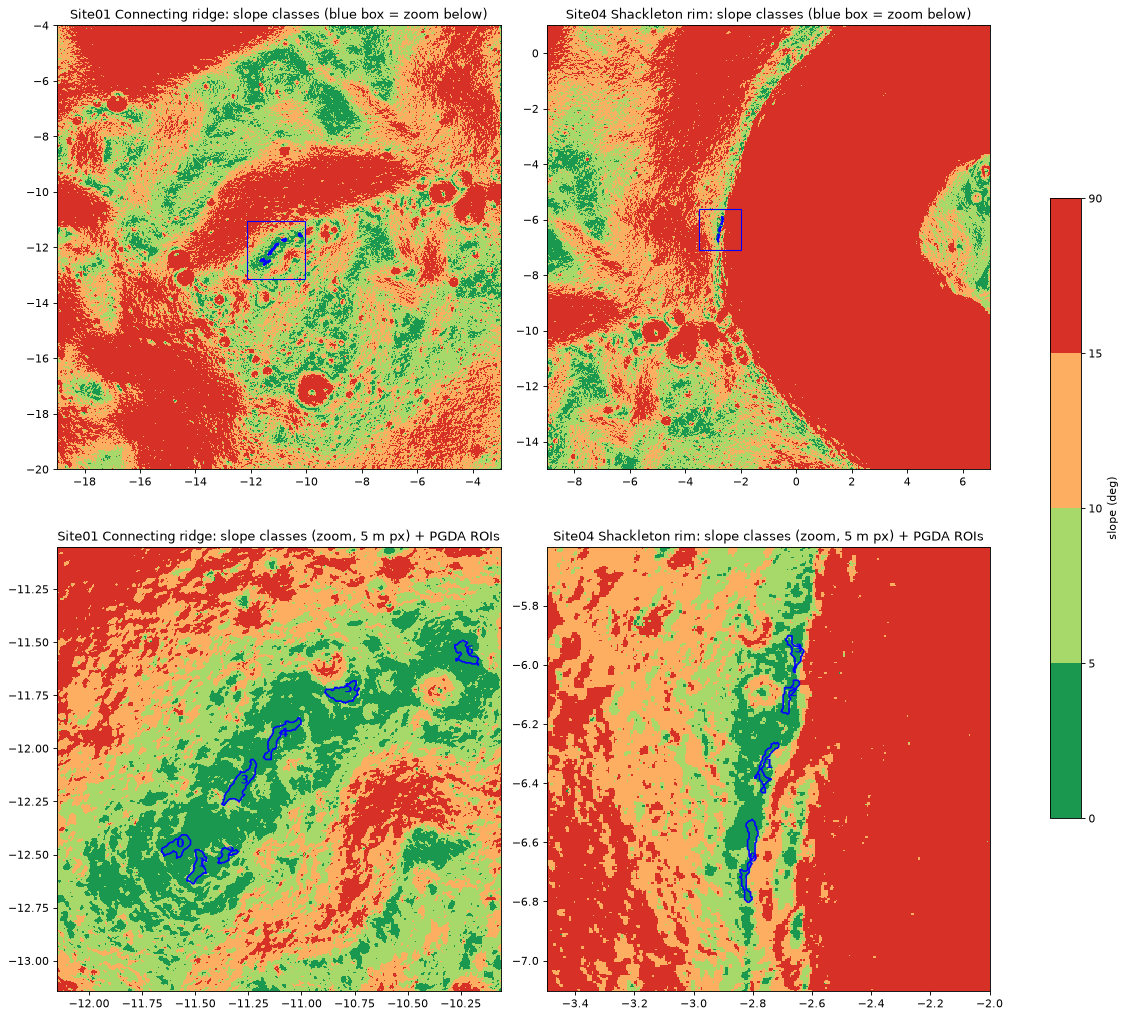

In [8]:
from matplotlib.colors import BoundaryNorm, ListedColormap
cm = ListedColormap(["#1a9850", "#a6d96a", "#fdae61", "#d73027"])
fig, axs = plt.subplots(2, 2, figsize=(14, 13), constrained_layout=True)
for i, s in enumerate(PG):
    allp = np.vstack(ROIS[s])
    cx, cy = allp.mean(0)
    half = max(np.ptp(allp[:, 0]), np.ptp(allp[:, 1])) / 2 + 300
    for ax, zoom in ((axs[0, i], False), (axs[1, i], True)):
        im = ax.imshow(ARR[s, "slp"] if zoom else coarse(ARR[s, "slp"], 4), extent=ext(s), cmap=cm,
                       norm=BoundaryNorm([0, 5, 10, 15, 90], 4), interpolation="nearest")
        for k, poly in enumerate(ROIS[s]):
            ax.plot(poly[:, 0] / 1e3, poly[:, 1] / 1e3, "b-", lw=1.5)
            if zoom:
                ax.text(poly[:, 0].mean() / 1e3, poly[:, 1].mean() / 1e3, str(k), color="b", fontsize=11, weight="bold")
        if zoom:
            ax.set_xlim((cx - half) / 1e3, (cx + half) / 1e3); ax.set_ylim((cy - half) / 1e3, (cy + half) / 1e3)
        else:
            ax.add_patch(plt.Rectangle(((cx - half) / 1e3, (cy - half) / 1e3), 2 * half / 1e3, 2 * half / 1e3, fill=False, ec="b"))
        ax.set_title(f"{s} {SITES[s]}: slope classes" + (" (zoom, 5 m px) + PGDA ROIs" if zoom else " (blue box = zoom below)"))
fig.colorbar(im, ax=axs, ticks=[0, 5, 10, 15, 90], shrink=0.6, label="slope (deg)")
plt.show()

**Findings.** Connecting Ridge (Site01) is the gentler site: roughly a third of the tile is under 10°, versus well under a
quarter at Shackleton Rim (Site04, dominated by the 4 km deep crater walls). Typical landers require < 8–15° at the footprint,
so in both tiles the flat ground is concentrated on ridge crests, exactly where the high-illumination ROIs sit.
The ROIs are **tiny** (a few thousand to ~13 000 m², i.e. patches ~50–120 m across: 7 strung along the Connecting Ridge crest,
4 on the Shackleton rim) and **very flat** (mean slope 2–3°, 100% of pixels < 10°): PGDA picked spots that are both well lit and
landable. Caveats: slope is a 5 m-baseline product, so lander-scale roughness (< 5 m) and boulders are *not* captured, and only
~5–15% of ROI pixels contain a LOLA shot: the rest is interpolated. App implication: the "good" places are pinpoints, so the
UI must let users zoom to 5 m resolution and should snap candidate landing points to such patches.

## 4. Azimuth conventions: Horizons vs south polar stereographic

JPL Horizons gives azimuth **from local north, clockwise toward east**. On the polar stereographic grid
(x right, y up) the point at east longitude λ sits at

$$x = \rho\sin\lambda,\qquad y = \rho\cos\lambda \qquad(\text{south polar stereographic, } \lambda_0=0)$$

so **local north** (away from the south pole, toward lower |latitude|) is the radial unit vector $(x, y)/\rho$, whose *grid azimuth*
(measured from grid +y, clockwise toward +x) is just λ. Local east is $\partial/\partial\lambda \propto (\cos\lambda, -\sin\lambda)$, grid
azimuth λ + 90°. Both are rotations of the same clockwise sense (the projection is conformal and not mirrored), hence

$$\boxed{\theta_\text{grid} = A_\text{Horizons} + \lambda,\qquad \lambda = \operatorname{atan2}(x, y)}$$

Grid +y is **not** north: at Site01 (λ ≈ 222.5°) local north points toward the lower-left of the map.
The cell below verifies this against pyproj (step a few metres north / east and measure the grid direction), and checks
it physically: the Earth hangs over the near side (sub-Earth longitude ≈ 0°), i.e. the grid +y direction, so the Earth's
grid azimuth must stay near 0° (± libration) from *both* sites, even though their local Earth azimuths differ.

In [9]:
def grid_az(local_az, x, y):
    # Horizons azimuth (from local north, clockwise to east) -> map azimuth (from grid +y, clockwise to +x), degrees.
    return (np.asarray(local_az) + np.degrees(np.arctan2(x, y))) % 360

def load_track(s, body):
    return pd.read_csv(ROOT / "data/raw/horizons" / f"{PG[s]}_{body}.csv", parse_dates=["time_utc"])

TRK, REF = {}, {}
for s, hz in PG.items():
    lat, lon = HZ_SITES[hz]
    x, y = REF[s] = to_xy.transform(lon, lat)
    xn, yn = to_xy.transform(lon, lat + 1e-4)
    xe, ye = to_xy.transform(lon + 1e-2, lat)
    pn, pe = np.degrees(np.arctan2(xn - x, yn - y)) % 360, np.degrees(np.arctan2(xe - x, ye - y)) % 360
    print(f"{s}: grid az of local north  pyproj {pn:7.3f}  formula {grid_az(0, x, y):7.3f} | "
          f"local east  pyproj {pe:7.3f}  formula {grid_az(90, x, y):7.3f}")
    assert abs(pn - grid_az(0, x, y)) < 0.01 and abs(pe - grid_az(90, x, y)) < 0.01
    for body in ("sun", "earth"):
        TRK[s, body] = load_track(s, body)
    e = TRK[s, "earth"]
    ga = (grid_az(e.az_deg, x, y) + 180) % 360 - 180
    print(f"   Earth: local az {e.az_deg.min():.0f}..{e.az_deg.max():.0f} deg, grid az {ga.min():+.1f}..{ga.max():+.1f} deg, "
          f"el {e.el_deg.min():+.2f}..{e.el_deg.max():+.2f};  Sun el {TRK[s,'sun'].el_deg.min():+.2f}..{TRK[s,'sun'].el_deg.max():+.2f}")

Site01: grid az of local north  pyproj 222.510  formula 222.510 | local east  pyproj 312.515  formula 312.510
   Earth: local az 130..145 deg, grid az -7.9..+7.6 deg, el -7.52..+6.14;  Sun el -2.11..+2.05
Site04: grid az of local north  pyproj 187.998  formula 187.998 | local east  pyproj 278.003  formula 277.998
   Earth: local az 164..180 deg, grid az -7.9..+7.6 deg, el -7.34..+6.29;  Sun el -1.82..+1.78


The pyproj check passes, and the Earth's grid azimuth stays within a few degrees of 0 from both sites (libration),
while its *local* azimuth is ≈ 137° at Connecting Ridge and ≈ 172° at Shackleton Rim, just as the formula predicts.
In the rest of the notebook horizons are computed in **grid azimuth**: a Sun or Earth direction is then (to < 0.01°) the
same for every pixel of the tile, which is what makes whole-tile maps cheap (section 7).

## 5. The key algorithm: terrain horizon by ray-marching with lunar curvature

For each of 360 azimuths, sample the DEM (bilinear) along a ray every 5 m out to the tile edge. A terrain point at
arc distance *d* and height *z* seen from an observer at height $z_0$ (DEM + mast height $h$) has elevation angle

$$\tan e = \frac{(R+z)\cos(d/R) - (R+z_0)}{(R+z)\sin(d/R)} \;\approx\; \frac{z - z_0}{d} - \frac{d}{2R}$$

i.e. the surface drops by $d^2/2R$: 0.7 m at 1.6 km, 18 m at 8 km, 74 m at 16 km (−0.26° at 16 km, comparable to the
solar radius and to the Sun's ±1.5° excursion at the pole, so it **must** be included). The horizon is the max over the ray.
Everything is vectorised: 360 rays × ~4 500 samples = 1.6 M bilinear lookups per point.

In [10]:
def horizon(Z, tr, x0, y0, h_obs=2.0, n_az=360, step=None, curvature=True):
    # Horizon elevation (deg) per map azimuth (deg from grid +y, clockwise) and distance (m) of the blocking terrain.
    step = step or abs(tr.a)
    H, W = Z.shape
    cx, cy = tr.c + np.array([0, W]) * tr.a, tr.f + np.array([0, H]) * tr.e
    dmax = np.hypot(cx[:, None] - x0, cy[None, :] - y0).max()
    az = np.arange(n_az) * 360 / n_az
    d = np.arange(1, int(dmax / step) + 1) * step
    th = np.radians(az)[:, None]
    zt = bilinear(Z, tr, x0 + d * np.sin(th), y0 + d * np.cos(th))
    z0 = bilinear(Z, tr, x0, y0) + h_obs
    if curvature:
        g = d / R
        el = np.degrees(np.arctan2((R + zt) * np.cos(g) - (R + z0), (R + zt) * np.sin(g)))
    else:
        el = np.degrees(np.arctan2(zt - z0, d))
    el = np.where(np.isnan(el), -np.inf, el)
    k = el.argmax(1)
    return az, el[np.arange(n_az), k], d[k]

# self-check: a perfectly smooth sphere (flat DEM) has horizon = -dmax/(2R) at the far edge
_az, _h, _d = horizon(np.zeros((200, 200), np.float32), Affine(5, 0, 0, 0, -5, 1000), 500, 500, h_obs=0)
assert np.allclose(_h, np.degrees(-_d / (2 * R)), atol=1e-4), "curvature check failed"

# Observation points: A = Horizons point (DEM centre); B = centroid of the largest PGDA ROI
PTS = {}
for s in PG:
    big = ROI_TAB[ROI_TAB.site == s].sort_values("area_m2").iloc[-1]
    PTS[s, "A"] = REF[s]
    PTS[s, "B"] = (big.cx_m, big.cy_m)
HZN, timing = {}, []
for (s, p), (x, y) in PTS.items():
    t0 = time.perf_counter()
    HZN[s, p] = horizon(ARR[s, "surf"], TR[s], x, y)
    timing.append((time.perf_counter() - t0) * 1e3)
    HZN[s, p, "flat"] = horizon(ARR[s, "surf"], TR[s], x, y, curvature=False)
    HZN[s, p, "10m"] = horizon(ARR[s, "surf"], TR[s], x, y, h_obs=10.0)
print(f"one 5 m horizon (360 az, full tile): {np.mean(timing):.0f} ms on average (numpy, single thread)")

one 5 m horizon (360 az, full tile): 224 ms on average (numpy, single thread)


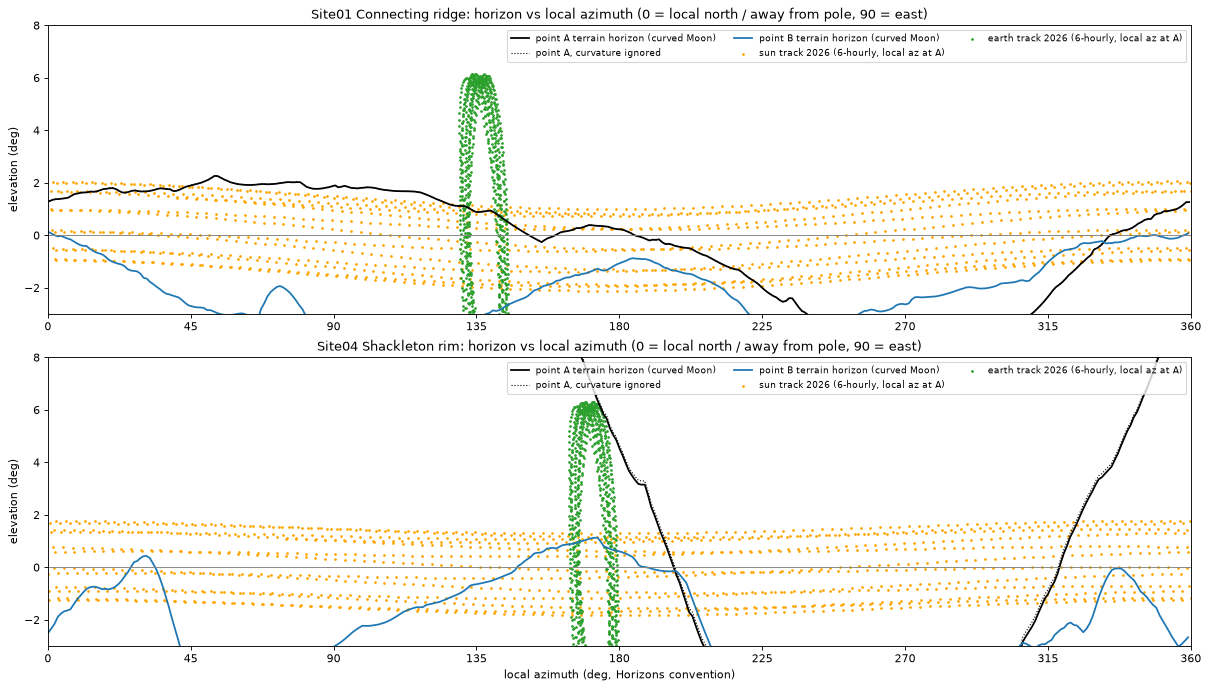

In [11]:
fig, axs = plt.subplots(2, 1, figsize=(15, 8.5), constrained_layout=True)
for ax, s in zip(axs, PG):
    lam = np.degrees(np.arctan2(*REF[s]))
    for p, c in (("A", "k"), ("B", "tab:blue")):
        az, h, _ = HZN[s, p]
        loc = (az - np.degrees(np.arctan2(*PTS[s, p]))) % 360   # grid -> local azimuth at that point
        o = np.argsort(loc)
        ax.plot(loc[o], h[o], c, lw=1.6, label=f"point {p} terrain horizon (curved Moon)")
        if p == "A":
            ax.plot(loc[o], HZN[s, p, "flat"][1][o], "k:", lw=1, label="point A, curvature ignored")
    for body, c in (("sun", "orange"), ("earth", "tab:green")):
        t = TRK[s, body].iloc[::6]
        ax.scatter(t.az_deg, t.el_deg, s=2, c=c, label=f"{body} track 2026 (6-hourly, local az at A)")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlim(0, 360); ax.set_ylim(-3, 8); ax.set_xticks(range(0, 361, 45))
    ax.set_title(f"{s} {SITES[s]}: horizon vs local azimuth (0 = local north / away from pole, 90 = east)")
    ax.set_ylabel("elevation (deg)"); ax.legend(fontsize=8, ncol=3, loc="upper right")
axs[1].set_xlabel("local azimuth (deg, Horizons convention)")
plt.show()

**Reading the plot.**
* **Site01 point A** (DEM centre, 1945 m on the ridge) has a +1…2° horizon over local azimuths 0–130°. That blocking is
  **near-field**: ground only 5–10 m higher at 85–265 m away. Toward the pole (180–330°) the horizon is below 0° because the
  Moon curves away from a high ridge. Result: 46% sunlit, but **88% with a 10 m mast** (table below).
* **Site01 point B** (largest PGDA ROI, on the crest 1.1 km away) has a horizon below 0° almost everywhere, so it sees the Sun
  even when the Sun is *below the smooth horizon*: 90% sunlit.
* **Site04 point A** (DEM centre) is on Shackleton's inner wall (764 m, ~1 km below the rim): the crater side rises past 8°
  and the Earth is never visible. Point B, an ROI on the rim, is clear: 83% sunlit.
* The Sun (orange) stays in a ±2° band and sweeps all azimuths every synodic month. The Earth (green) swings only about ±8° in azimuth
  around the near-side direction, so **Earth visibility depends on one narrow horizon sector**.
* Ignoring curvature (dotted) barely matters *here* (≤ 0.3 percentage points), because the blocking terrain is close.
  The d²/2R drop grows quadratically, though: it is −0.26° at 16 km and −2.9° at 100 km, so it dominates once rays are extended
  beyond the tile (section 6).

### Terrain-aware vs smooth-horizon sunlight and Earth visibility (2026, hourly)
For a point P displaced by Δ from the Horizons reference point, a body in grid direction **u** appears higher by
(Δ·**u**)/R radians (the local vertical tilts by Δ/R); azimuths in grid frame are unchanged. "Sun any limb" counts an hour
lit if the top of the solar disk clears the horizon (el + 0.27° > horizon), a proxy for partial illumination.

In [12]:
def body_vis(s, body, x, y, az_grid, hz, margin=0.0):
    # Hourly boolean: body clears terrain horizon hz(az_grid) at map point (x, y); ephemeris from site s reference point.
    t = TRK[s, body]
    th = np.radians(grid_az(t.az_deg.values, *REF[s]))
    el = t.el_deg.values + np.degrees(((x - REF[s][0]) * np.sin(th) + (y - REF[s][1]) * np.cos(th)) / R)
    return el + margin > np.interp(np.degrees(th), az_grid, hz, period=360)

def longest_run(m):
    d = np.diff(np.r_[0, m.astype(np.int8), 0])
    return (np.flatnonzero(d == -1) - np.flatnonzero(d == 1)).max(initial=0)

rows, VIS = [], {}
for (s, p), (x, y) in PTS.items():
    az, h, _ = HZN[s, p]
    sun_s, earth_s = TRK[s, "sun"].el_deg.values > 0, TRK[s, "earth"].el_deg.values > 0
    sun_t, earth_t = body_vis(s, "sun", x, y, az, h), body_vis(s, "earth", x, y, az, h)
    VIS[s, p] = sun_t, earth_t
    rows.append({"site": s, "point": p, "z (m)": float(bilinear(ARR[s, "surf"], TR[s], x, y)),
                 "Sun smooth %": 100 * sun_s.mean(), "Sun terrain %": 100 * sun_t.mean(),
                 "Sun any-limb terrain %": 100 * body_vis(s, "sun", x, y, az, h, SUN_R).mean(),
                 "Sun terrain, 10 m mast %": 100 * body_vis(s, "sun", x, y, *HZN[s, p, "10m"][:2]).mean(),
                 "Sun terrain, no curvature %": 100 * body_vis(s, "sun", x, y, *HZN[s, p, "flat"][:2]).mean(),
                 "Earth smooth %": 100 * earth_s.mean(), "Earth terrain %": 100 * earth_t.mean(),
                 "Sun & Earth terrain %": 100 * (sun_t & earth_t).mean(),
                 "longest dark (h) smooth": longest_run(~sun_s), "longest dark (h) terrain": longest_run(~sun_t),
                 "longest no-Earth (d) terrain": longest_run(~earth_t) / 24})
FRAC = pd.DataFrame(rows).set_index(["site", "point"])
FRAC.round(1).T

site                          Site01          Site04        
point                              A       B       A       B
z (m)                         1944.8  1956.4   764.1  1728.1
Sun smooth %                    52.5    52.5    49.8    49.8
Sun terrain %                   46.4    90.0    32.9    82.9
Sun any-limb terrain %          51.4    92.2    33.5    86.1
Sun terrain, 10 m mast %        87.9    98.1    33.1    91.5
Sun terrain, no curvature %     46.3    90.0    32.6    82.6
Earth smooth %                  44.0    44.0    44.7    44.7
Earth terrain %                 39.7    58.7     0.0    42.1
Sun & Earth terrain %           19.1    52.3     0.0    36.9
longest dark (h) smooth       3408.0  3408.0  4055.0  4055.0
longest dark (h) terrain       506.0   128.0   489.0   181.0
longest no-Earth (d) terrain    16.7    11.5   365.0    16.0

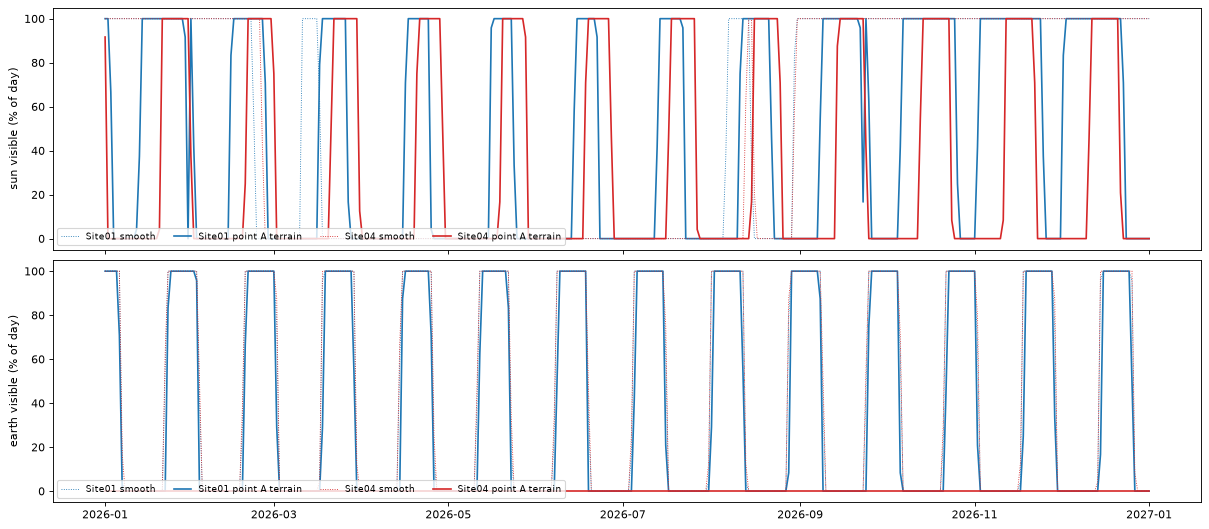

In [13]:
fig, axs = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True, constrained_layout=True)
for ax, body in zip(axs, ("sun", "earth")):
    for s, c in zip(PG, ("tab:blue", "tab:red")):
        t = TRK[s, body].set_index("time_utc")
        ax.plot((t.el_deg > 0).resample("D").mean() * 100, c, lw=0.8, ls=":", label=f"{s} smooth")
        vis = pd.Series(VIS[s, "A"][0 if body == "sun" else 1], index=t.index)
        ax.plot(vis.resample("D").mean() * 100, c, lw=1.5, label=f"{s} point A terrain")
    ax.set_ylabel(f"{body} visible (% of day)"); ax.legend(fontsize=8, ncol=4, loc="lower left")
plt.show()

## 6. The 16 km tile limits the horizon

Inside the tile every ray stops at the edge, 5–14 km from the centre. Beyond that the code assumes "nothing", so distant
terrain that could block the Sun is missing and **the terrain-aware fractions above are upper bounds for sunlight**.
How far is far enough? A massif ΔH above the observer at distance *d* subtends roughly ΔH/d − d/2R:

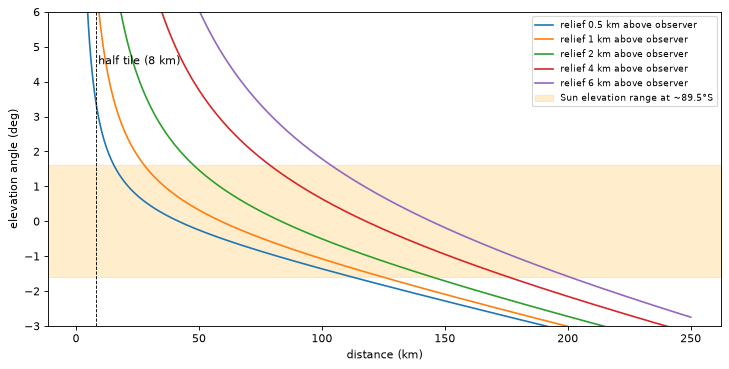

In [14]:
d = np.linspace(1, 250, 500) * 1e3
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for dh in (0.5, 1, 2, 4, 6):
    ax.plot(d / 1e3, np.degrees(dh * 1e3 / d - d / (2 * R)), label=f"relief {dh} km above observer")
ax.axhspan(-1.6, 1.6, color="orange", alpha=0.2, label="Sun elevation range at ~89.5°S")
ax.axvline(8, color="k", ls="--", lw=0.8); ax.text(9, 4.5, "half tile (8 km)")
ax.set_ylim(-3, 6); ax.set_xlabel("distance (km)"); ax.set_ylabel("elevation angle (deg)"); ax.legend(fontsize=8)
plt.show()

Kilometre-high relief stays above the Sun's elevation band out to ~50–150 km (e.g. Malapert massif, Leibnitz β, ~100–120 km
from the pole). So a 5 m, 16 km tile is the right tool for the *near field* (local blocking by rims and boulders-scale slopes)
but cannot settle the far field. **Real-data demonstration:** the Site01 and Site04 tiles overlap, so we can mosaic them into a
26×21 km DEM and see how the horizons change when the neighbour's terrain becomes visible.

In [15]:
left, top = min(BND[s].left for s in PG), max(BND[s].top for s in PG)
right, bottom = max(BND[s].right for s in PG), min(BND[s].bottom for s in PG)
MOS = np.full((int((top - bottom) / 5), int((right - left) / 5)), np.nan, np.float32)
TRM = Affine(5, 0, left, 0, -5, top)
win = {s: (slice(int((top - BND[s].top) / 5), int((top - BND[s].bottom) / 5)),
           slice(int((BND[s].left - left) / 5), int((BND[s].right - left) / 5))) for s in PG}
MOS[win["Site04"]] = ARR["Site04", "surf"]
ov = np.isfinite(MOS[win["Site01"]])
dz = (ARR["Site01", "surf"] - MOS[win["Site01"]])[ov]
print(f"overlap {ov.sum()*25/1e6:.0f} km2: Site01 - Site04 height median {np.median(dz):+.2f} m, "
      f"robust std {1.4826*np.median(np.abs(dz-np.median(dz))):.2f} m, p99 |dz| {np.percentile(np.abs(dz), 99):.2f} m")
MOS[win["Site01"]] = ARR["Site01", "surf"]

rows = []
for (s, p), (x, y) in PTS.items():
    az, h, dist = horizon(MOS, TRM, x, y)
    sun_m, earth_m = body_vis(s, "sun", x, y, az, h), body_vis(s, "earth", x, y, az, h)
    h0 = HZN[s, p][1]
    rows.append({"site": s, "point": p, "az with higher horizon %": 100 * (h > h0 + 0.01).mean(),
                 "max horizon rise (deg)": (h - h0).max(), "Sun terrain % (tile)": FRAC.loc[(s, p), "Sun terrain %"],
                 "Sun terrain % (mosaic)": 100 * sun_m.mean(), "Earth terrain % (tile)": FRAC.loc[(s, p), "Earth terrain %"],
                 "Earth terrain % (mosaic)": 100 * earth_m.mean()})
    HZN[s, p, "mos"] = az, h, dist
pd.DataFrame(rows).round(2)

overlap 66 km2: Site01 - Site04 height median +0.07 m, robust std 0.14 m, p99 |dz| 1.30 m


,site,point,az with higher horizon %,max horizon rise (deg),Sun terrain % (tile),Sun terrain % (mosaic),Earth terrain % (tile),Earth terrain % (mosaic)
0,Site01,A,0.28,0.03,46.39,46.39,39.72,39.72
1,Site01,B,6.67,1.17,90.02,90.02,58.75,58.75
2,Site04,A,0.00,0.00,32.93,32.93,0.00,0.00
3,Site04,B,19.44,4.35,82.91,80.37,42.06,42.06


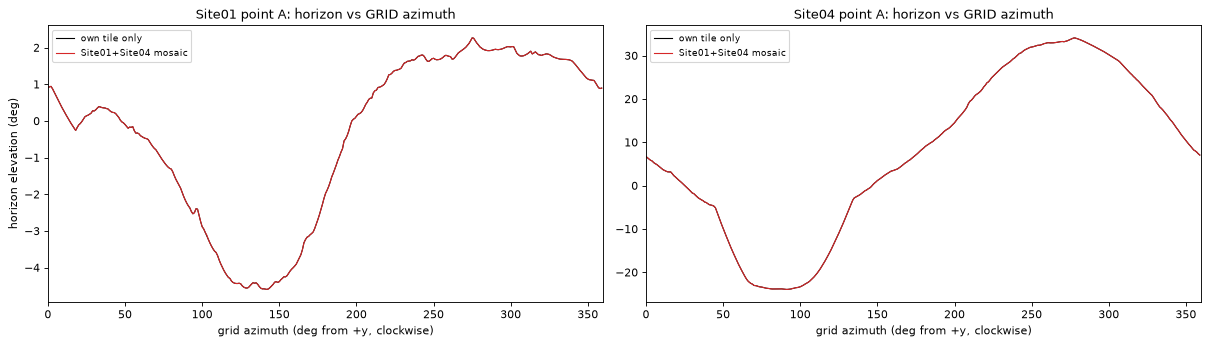

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2), constrained_layout=True)
for ax, s in zip(axs, PG):
    az, h, _ = HZN[s, "A"]
    ax.plot(az, h, "k", lw=1, label="own tile only")
    ax.plot(az, HZN[s, "A", "mos"][1], "tab:red", lw=1, label="Site01+Site04 mosaic")
    ax.set_title(f"{s} point A: horizon vs GRID azimuth"); ax.set_xlabel("grid azimuth (deg from +y, clockwise)")
    ax.set_xlim(0, 360); ax.legend(fontsize=8)
axs[0].set_ylabel("horizon elevation (deg)")
plt.show()

**Implications.** The two independently produced PGDA tiles agree where they overlap (median Δz +0.07 m, robust std 0.14 m),
so tiles can be mosaicked safely. In this case the extra terrain changes little: the horizons of both A points and of Site01 B are
nearly unchanged. Site04 B's horizon rises by up to 4.4° over 19% of azimuths (the connecting ridge, now in view), and its
sunlight drops from 82.9% to 80.4%. The large far-field blockers (Malapert, Leibnitz β, de Gerlache–Kocher: 50–150 km away)
are in *neither* tile, so every terrain fraction in this notebook is still an **upper bound for sunlight**.

For the app, use a **two-scale horizon**: ray-march the 5 m tile for the first ~5–10 km, then continue the same rays on a
coarser, wider polar DEM (e.g. LOLA `LDEM_875S_20M` / `LDEM_85S_40M`-class PDS polar grids, or the DEM behind Trek's
`LRO_LOLA_DEM_SPole875`) out to ~150–200 km, and take the max over both. Far terrain does not need fine resolution: a 40–120 m
pixel at 50 km subtends < 0.15°. Curvature must be included there. Trek's WMTS layers are rendered PNGs, so the heights must come
from a raw-value DEM (PDS/PGDA).

## 7. Whole-tile maps: sunlight and Earth-visibility fractions (precompute prototype)
Horizon on a 24×24 grid of points per tile (≈ 670 m spacing), using the DEM block-averaged to 20 m and 20 m ray steps (4× fewer samples than 5 m).
Because Sun/Earth directions are expressed in grid azimuth, one ephemeris table serves every point (with the Δ·u/R tilt correction).

In [17]:
def vis_map(s, n=24):
    f = 4
    Zc, trc = coarse(ARR[s, "surf"], f), TR[s] * Affine.scale(f)
    b = BND[s]
    xs = np.linspace(b.left + 250, b.right - 250, n)
    ys = np.linspace(b.top - 250, b.bottom + 250, n)
    X, Y = np.meshgrid(xs, ys)
    t0 = time.perf_counter()
    Hs = np.array([horizon(Zc, trc, x, y, step=20)[1] for x, y in zip(X.ravel(), Y.ravel())])
    dt = time.perf_counter() - t0
    out = {}
    for body in ("sun", "earth"):
        t = TRK[s, body]
        th = np.radians(grid_az(t.az_deg.values, *REF[s]))
        el = t.el_deg.values[None, :] + np.degrees(((X.ravel() - REF[s][0])[:, None] * np.sin(th)
                                                    + (Y.ravel() - REF[s][1])[:, None] * np.cos(th)) / R)
        idx = np.rint(np.degrees(th)).astype(int) % 360  # nearest 1-deg horizon bin
        out[body] = (el > Hs[:, idx]).mean(1).reshape(n, n) * 100
    return X, Y, out, dt, len(Hs)

MAPS = {s: vis_map(s) for s in PG}
for s, (X, Y, out, dt, n) in MAPS.items():
    print(f"{s}: {n} horizons at 20 m in {dt:.1f} s ({dt/n*1e3:.0f} ms each)")

Site01: 576 horizons at 20 m in 43.1 s (75 ms each)
Site04: 576 horizons at 20 m in 43.7 s (76 ms each)


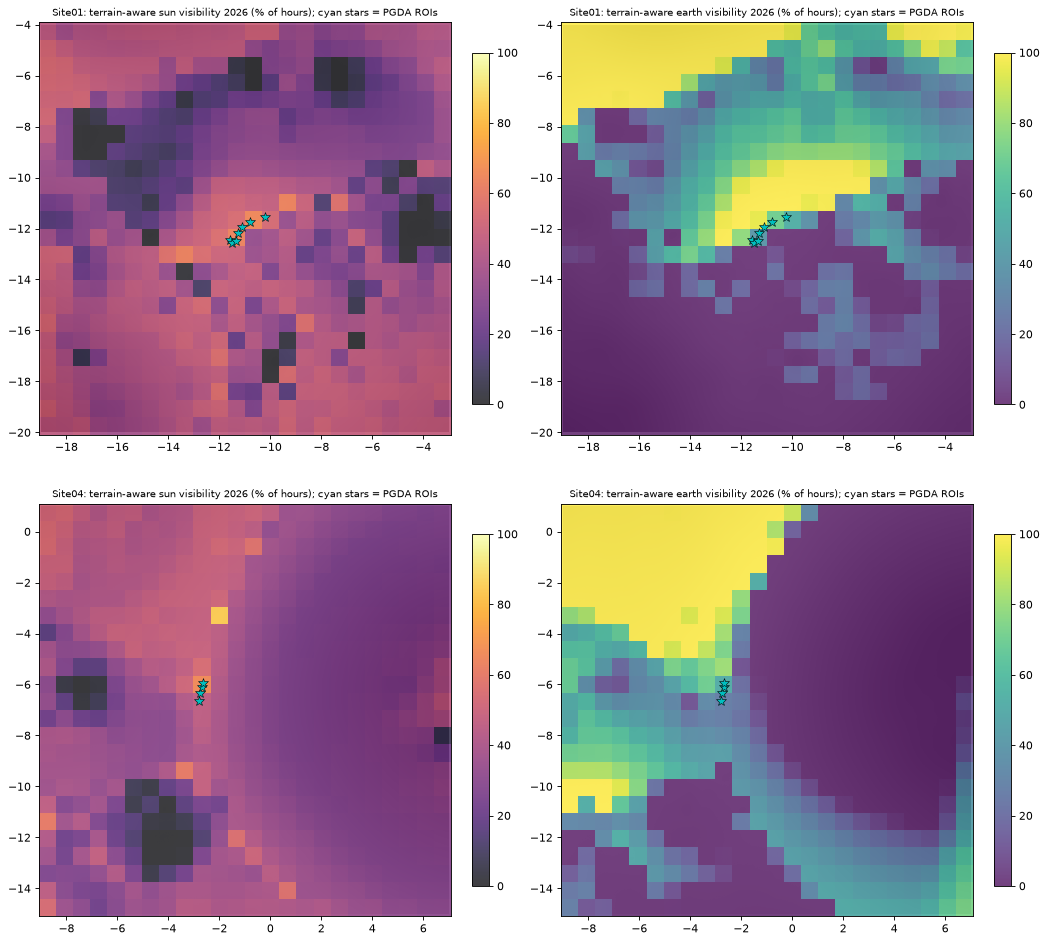

,site,roi,Sun terrain %,Earth terrain %,tile map points with less Sun %
0,Site01,0,87.6,58.9,100.0
1,Site01,1,85.0,50.2,100.0
2,Site01,2,79.4,46.2,100.0
3,Site01,3,90.2,59.0,100.0
4,Site01,4,85.7,55.5,100.0
5,Site01,5,92.8,69.2,100.0
6,Site01,6,88.3,60.1,100.0
7,Site04,0,85.3,42.5,100.0
8,Site04,1,79.9,43.0,99.8
9,Site04,2,89.8,50.8,100.0


,count,mean,std,min,50%,90%,99%,max
Site01,576.000000,34.500000,14.000000,0.000000,37.800000,48.900000,56.400000,65.400000
Site04,576.000000,33.500000,10.400000,0.000000,31.700000,47.200000,55.900000,84.400000


In [18]:
fig, axs = plt.subplots(2, 2, figsize=(13, 12), constrained_layout=True)
for i, s in enumerate(PG):
    X, Y, out, *_ = MAPS[s]
    for j, (body, cmap) in enumerate((("sun", "inferno"), ("earth", "viridis"))):
        ax = axs[i, j]
        ax.imshow(coarse(ARR[s, "surf"], 8), extent=ext(s), cmap="gray", alpha=0.5)
        im = ax.pcolormesh(X / 1e3, Y / 1e3, out[body], cmap=cmap, vmin=0, vmax=100, alpha=0.75, shading="nearest")
        for poly in ROIS[s]:
            ax.plot(*poly.mean(0) / 1e3, "c*", ms=9, mec="k", mew=0.5)
        ax.set_title(f"{s}: terrain-aware {body} visibility 2026 (% of hours); cyan stars = PGDA ROIs", fontsize=9)
        fig.colorbar(im, ax=ax, shrink=0.75)
plt.show()

# ROIs are ~100 m patches, smaller than the 670 m map spacing: evaluate them directly, same 20 m method
rows = []
for s in PG:
    X, Y, out, *_ = MAPS[s]
    Zc, trc = coarse(ARR[s, "surf"], 4), TR[s] * Affine.scale(4)
    for k, poly in enumerate(ROIS[s]):
        cx, cy = poly.mean(0)
        az, h, _ = horizon(Zc, trc, cx, cy, step=20)
        sun = 100 * body_vis(s, "sun", cx, cy, az, h).mean()
        rows.append({"site": s, "roi": k, "Sun terrain %": sun, "Earth terrain %": 100 * body_vis(s, "earth", cx, cy, az, h).mean(),
                     "tile map points with less Sun %": 100 * (out["sun"] < sun).mean()})
display(pd.DataFrame(rows).round(1))
pd.DataFrame({s: pd.Series(MAPS[s][2]["sun"].ravel()).describe(percentiles=[.5, .9, .99]) for s in PG}).round(1).T.style.set_caption("Sun % over the map grid")

**Validation and caveats.**
* PGDA chose its ROIs independently, as "average illumination > 70%". All 11 ROIs score 79–93% sunlit here, at the
  **≥ 99.8th percentile** of the tile map, while the map median is only ~30–40%. A wrong azimuth convention would scramble this
  match, so it is good evidence that the azimuth conversion, curvature and tilt correction are right.
* Our values are *higher* than PGDA's for three reasons: (a) the horizon only reaches the tile edge (section 6), (b) we test the Sun's
  centre, not the visible fraction of the disk, and (c) we cover one year (2026), not a multi-year average.
* **Edge artefacts:** the yellow 100% Earth-visibility bands sit along the Earth-facing (+y) edges, where Earth-ward rays leave the
  DEM within a few hundred metres. They are not real; the tile limit appears directly in the map.
* The map grid (≈ 670 m) is far coarser than the ~100 m ROIs: sunlight changes over tens of metres, so maps for decisions need
  ≤ 50 m spacing.

## 8. Performance notes for the web app

Measured here (numpy, one thread): one 5 m full-tile horizon (360 rays × ~4 500 samples ≈ 1.6 M bilinear lookups) takes ≈ 200 ms.
A 20 m horizon takes ≈ 75 ms, and the 576-point map ≈ 43 s per tile. At 50 m spacing, a whole 16 km tile is ~100 k horizons:
≈ 2 h single-threaded numpy, minutes on a GPU or in parallel. That is an offline job, not a page-load job.

Recommended design:
* **Precompute horizon masks offline** for a grid of candidate points (e.g. every 50–100 m on the 5 m DEM, two-scale rays to
  ~150 km): 360 azimuths × int16 (0.01° units) = 720 B/point → 160×160 points ≈ 18 MB per 16 km tile raw, a few MB
  compressed. Serve as a small binary tile or bake into PNG/WebP channels.
* **Ephemeris once per region**: convert the Horizons Sun/Earth az to grid azimuth at the reference point; any pixel's
  visibility is then `el + Δ·u/R > horizon[az]`, a lookup + compare → sunlight/Earth fractions for any date window are
  instant in the browser (8 760 hours × a few comparisons).
* **On-the-fly for arbitrary clicks**: a 20 m single-point horizon (≈ 400 k samples) is ~10–50 ms in JS typed arrays or a WebGL/
  WebGPU shader; acceptable for an interactive "drop a pin" feature, with the far field taken from a precomputed coarse
  horizon map. Full-resolution 5 m rays (1.6 M samples) belong on a server/worker.
* Quantities worth precomputing per point: % sunlit, % Earth visible, % both, longest night (h) and longest Earth outage,
  for the mission's date window; plus `toterr`/`ldec` as a confidence layer and slope classes.

## 9. Summary

In [19]:
print(FRAC[["Sun smooth %", "Sun terrain %", "Earth smooth %", "Earth terrain %", "longest dark (h) smooth",
            "longest dark (h) terrain"]].round(1).to_string())

              Sun smooth %  Sun terrain %  Earth smooth %  Earth terrain %  longest dark (h) smooth  longest dark (h) terrain
site   point                                                                                                                 
Site01 A              52.5           46.4            44.0             39.7                     3408                       506
       B              52.5           90.0            44.0             58.7                     3408                       128
Site04 A              49.8           32.9            44.7              0.0                     4055                       489
       B              49.8           82.9            44.7             42.1                     4055                       181


**Key findings**
1. **Data:** 2 × 16 km tiles at 5 m/px, polar stereographic, no nodata. ~90% of pixels hold no LOLA shot (interpolated),
   ≈ 4 000 shots/km². Height error: median 0.37 m, p95 ≈ 0.8 m. Shot-vs-DEM robust std 0.24 m (Site01) and 0.38 m (Site04).
   Error is negligible for horizons, but 5 m details between ground tracks are uncertain.
2. **Slope:** Site01 has 36% of the tile below 10° (Site04: 19%). The PGDA high-illumination ROIs are ~100 m patches with mean slope 2–3°.
3. **Azimuth:** grid azimuth = Horizons azimuth + east longitude, verified with pyproj. The Earth sits at grid az ≈ 0 ± 8° from both sites.
4. **Terrain vs smooth horizon (2026, hourly, Sun centre):**

| point | Sun smooth | Sun terrain | Earth smooth | Earth terrain | longest dark, smooth → terrain |
|---|---|---|---|---|---|
| Site01 ROI (B) | 52.5% | **90.0%** | 44.0% | **58.7%** | 142 d → **5.3 d** (128 h) |
| Site01 centre (A) | 52.5% | 46.4% (87.9% with a 10 m mast) | 44.0% | 39.7% | 142 d → 21 d |
| Site04 ROI (B) | 49.8% | **82.9%** | 44.7% | **42.1%** | 169 d → **7.5 d** (181 h) |
| Site04 centre (A, crater wall) | 49.8% | 32.9% | 44.7% | **0%** | 169 d → 20 d |

   A smooth horizon is badly wrong at the pole in **both directions**. Elevated ridges see a Sun below 0° (90% vs 52%), while
   crater walls lose it (and the Earth) entirely. Answers change over 100 m–1 km, and mast height (2 m vs 10 m) can double sunlight.
5. **Tile limit:** sunlight figures are upper bounds. Mosaicking the overlapping tiles (they agree to 0.14 m) cut Site04 ROI sunlight
   from 82.9% to 80.4%. Far massifs 50–150 km away still need a wider, coarser DEM with curvature.

**App design:** precompute 360-azimuth horizon masks per point (two-scale rays, mast height as a parameter), convert the
ephemeris to grid azimuth once per region, and evaluate visibility in the browser as `el + Δ·u/R > horizon[az]`. Show the
`ldec`/`toterr` confidence layer and slope classes alongside.